# Project 2 – Neural network

## 1. Setup

In [1]:
%pip install lime shap umap-learn torch scikit-learn pandas numpy matplotlib scipy --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_TAG = 'NN'   # used in plot titles and file names

## 2. Data
### 2.1 Load data and make the binary target

In [3]:
# Loads the dataset
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\nOriginal 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):")
print(df["Diabetes_012"].value_counts().sort_index())

Dataset shape: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0



Original 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


In [4]:
# The task: does the person have prediabetes OR diabetes?  (Diabetes_012 = 1 or 2  ->  1)
df["Diabetes_binary"] = (df["Diabetes_012"] > 0).astype(float)

TARGET = "Diabetes_binary"
FEATURE_COLS = [c for c in df.columns if c not in ["Diabetes_012", TARGET]]
feature_names = FEATURE_COLS
class_names = ['No diabetes', 'Prediabetes/Diabetes']
pos_label = 1   # index of the positive class

print("Number of features:", len(FEATURE_COLS))
print("\nBinary target distribution:")
print(df[TARGET].value_counts().sort_index())

Number of features: 21

Binary target distribution:
Diabetes_binary
0.0    213703
1.0     39977
Name: count, dtype: int64


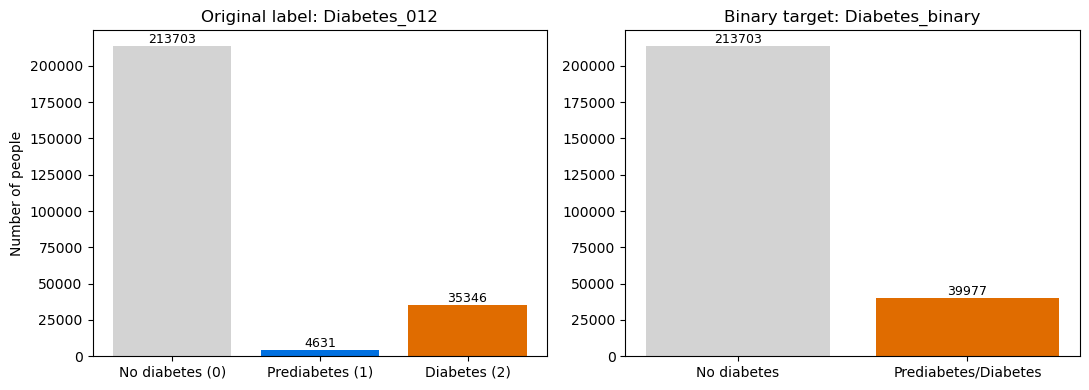

Share of positives (prediabetes or diabetes): 15.8%


In [5]:
# How imbalanced is the data?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts_012 = df['Diabetes_012'].value_counts().sort_index()
axes[0].bar(['No diabetes (0)', 'Prediabetes (1)', 'Diabetes (2)'], counts_012.values,
            color=['lightgray', '#0070e0', '#e06c00'])
axes[0].set_title('Original label: Diabetes_012')
axes[0].set_ylabel('Number of people')

counts_bin = df[TARGET].value_counts().sort_index()
axes[1].bar(class_names, counts_bin.values, color=['lightgray', '#e06c00'])
axes[1].set_title(f'Binary target: {TARGET}')

for ax in axes:
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

print(f'Share of positives (prediabetes or diabetes): {df[TARGET].mean():.1%}')

### 2.2 Train / validation / test split

In [6]:
# Separate features and target
X = df[FEATURE_COLS].to_numpy(dtype=np.float32)
y = df[TARGET].to_numpy(dtype=np.float32)
y012 = df["Diabetes_012"].to_numpy(dtype=int)   # only used to colour the latent-space plots

# Keep 20% completely separate for final testing
X_train_raw, X_test_raw, y_train, y_test, y012_train, y012_test = train_test_split(
    X, y, y012,
    test_size=0.20,
    random_state=SEED,
    stratify=y   # keeps approximately the same proportion of classes in both sets
)

# Make a validation set from the remaining data
X_train_raw, X_val_raw, y_train, y_val, y012_train, y012_val = train_test_split(
    X_train_raw, y_train, y012_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

print(f'Train: {X_train_raw.shape}, Validation: {X_val_raw.shape}, Test: {X_test_raw.shape}')
print(f'Share of positives  train: {y_train.mean():.3f}   val: {y_val.mean():.3f}   test: {y_test.mean():.3f}')

Train: (162355, 21), Validation: (40589, 21), Test: (50736, 21)
Share of positives  train: 0.158   val: 0.158   test: 0.158


### 2.3 Standardization

In [7]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (162355, 21)
Validation: (40589, 21)
Test: (50736, 21)


### 2.4 Class weights

In [8]:
n_neg = int(np.sum(y_train == 0))
n_pos = int(np.sum(y_train == 1))
pos_weight = n_neg / n_pos

print(f'Negatives in train: {n_neg}')
print(f'Positives in train: {n_pos}')
print(f'pos_weight = {n_neg} / {n_pos} = {pos_weight:.3f}')

Negatives in train: 136769
Positives in train: 25586
pos_weight = 136769 / 25586 = 5.345


### 2.5 Tensors and data loaders

In [9]:
# Convert data to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

batch_size = 256

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=batch_size,
    shuffle=False
)

## 3. Train the neural network

In [10]:
# This is our neural network (small and simple)

class DiabetesNN(nn.Module):
    def __init__(self, n_features):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(n_features, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


model = DiabetesNN(n_features=X_train.shape[1])

# BCEWithLogitsLoss already includes the sigmoid operation internally (BCE = Binary Cross Entropy)
# pos_weight gives the positive class more weight in the loss (class imbalance)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [11]:
# Train the model with simple early stopping

max_epochs = 100   # 1 epoch = the network has seen every training observation once
patience = 5       # if validation loss doesn't improve for 5 epochs in a row, stop training

best_val_loss = float("inf")
epochs_without_improvement = 0
best_model_state = None

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(max_epochs):

    # ----- Training -----
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

        predictions = (torch.sigmoid(logits) >= 0.5).float()
        correct += (predictions == y_batch).sum().item()
        total += y_batch.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # ----- Validation -----
    model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

            predictions = (torch.sigmoid(logits) >= 0.5).float()
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

    val_loss = running_val_loss / total
    val_accuracy = correct / total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.3f} | "
        f"val acc: {val_accuracy:.3f}"
    )

    # ----- Early stopping -----
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

# Use the weights from the epoch with the lowest validation loss
model.load_state_dict(best_model_state)

Epoch 01 | train loss: 0.8992 | val loss: 0.8643 | train acc: 0.716 | val acc: 0.697
Epoch 02 | train loss: 0.8649 | val loss: 0.8595 | train acc: 0.713 | val acc: 0.709
Epoch 03 | train loss: 0.8617 | val loss: 0.8579 | train acc: 0.715 | val acc: 0.706
Epoch 04 | train loss: 0.8601 | val loss: 0.8588 | train acc: 0.714 | val acc: 0.703
Epoch 05 | train loss: 0.8592 | val loss: 0.8581 | train acc: 0.715 | val acc: 0.725
Epoch 06 | train loss: 0.8584 | val loss: 0.8589 | train acc: 0.716 | val acc: 0.733
Epoch 07 | train loss: 0.8576 | val loss: 0.8572 | train acc: 0.717 | val acc: 0.716
Epoch 08 | train loss: 0.8567 | val loss: 0.8572 | train acc: 0.717 | val acc: 0.721
Epoch 09 | train loss: 0.8565 | val loss: 0.8584 | train acc: 0.717 | val acc: 0.725
Epoch 10 | train loss: 0.8557 | val loss: 0.8576 | train acc: 0.719 | val acc: 0.724
Epoch 11 | train loss: 0.8557 | val loss: 0.8582 | train acc: 0.719 | val acc: 0.705
Epoch 12 | train loss: 0.8551 | val loss: 0.8574 | train acc: 0.7

<All keys matched successfully>

### 3.1 Learning curves

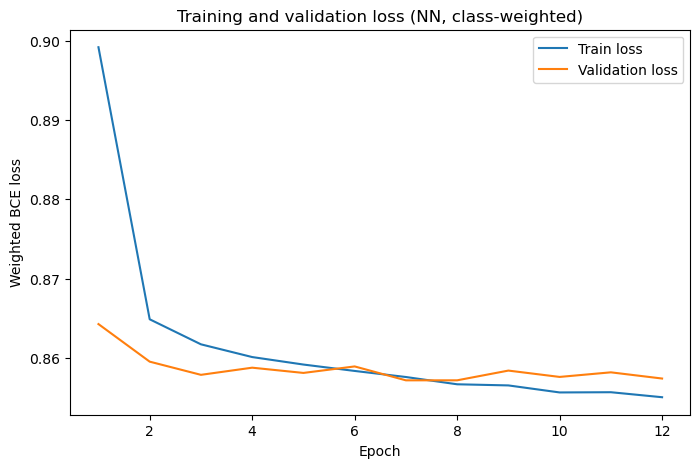

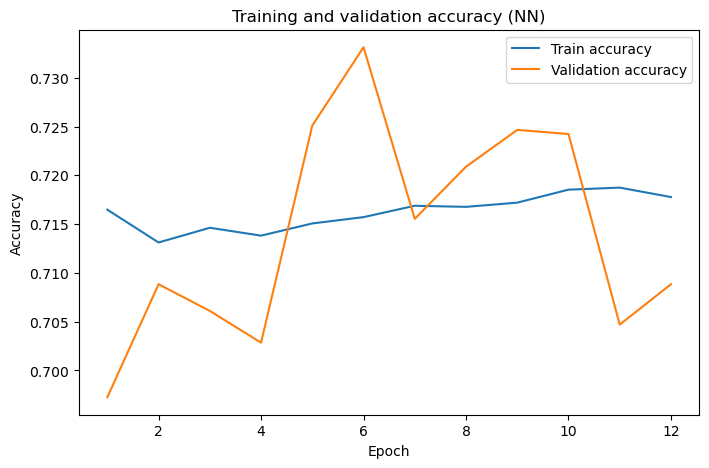

In [12]:
# Plot learning curves
epochs_run = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_run, train_losses, label="Train loss")
plt.plot(epochs_run, val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Weighted BCE loss")
plt.title("Training and validation loss (NN, class-weighted)")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_run, train_accuracies, label="Train accuracy")
plt.plot(epochs_run, val_accuracies, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy (NN)")
plt.legend()
plt.show()

### 3.2 Test-set evaluation

Test accuracy:          0.714
Test balanced accuracy: 0.746
ROC-AUC:                0.824
PR-AUC (avg precision): 0.460   (random model = 0.158)

Classification report:
                      precision    recall  f1-score   support

         No diabetes      0.947     0.699     0.805     42741
Prediabetes/Diabetes      0.330     0.792     0.466      7995

            accuracy                          0.714     50736
           macro avg      0.639     0.746     0.635     50736
        weighted avg      0.850     0.714     0.751     50736



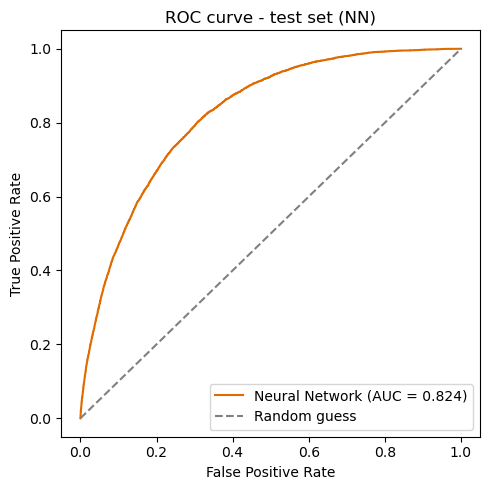

In [13]:
# Evaluation once on the untouched test set
model.eval()

with torch.no_grad():
    test_logits = model(X_test_t)
    test_probabilities = torch.sigmoid(test_logits).cpu().numpy().ravel()

test_predictions = (test_probabilities >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test, test_predictions)
test_bal_acc = balanced_accuracy_score(y_test, test_predictions)
test_auc = roc_auc_score(y_test, test_probabilities)
test_ap = average_precision_score(y_test, test_probabilities)

print(f"Test accuracy:          {test_accuracy:.3f}")
print(f"Test balanced accuracy: {test_bal_acc:.3f}")
print(f"ROC-AUC:                {test_auc:.3f}")
print(f"PR-AUC (avg precision): {test_ap:.3f}   (random model = {y_test.mean():.3f})")

print("\nClassification report:")
print(classification_report(y_test, test_predictions, target_names=class_names, digits=3))

fpr_nn, tpr_nn, _ = roc_curve(y_test, test_probabilities)

plt.figure(figsize=(5, 5))
plt.plot(fpr_nn, tpr_nn, label=f'Neural Network (AUC = {test_auc:.3f})', color='#e06c00')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve - test set (NN)')
plt.legend()
plt.tight_layout()
plt.show()

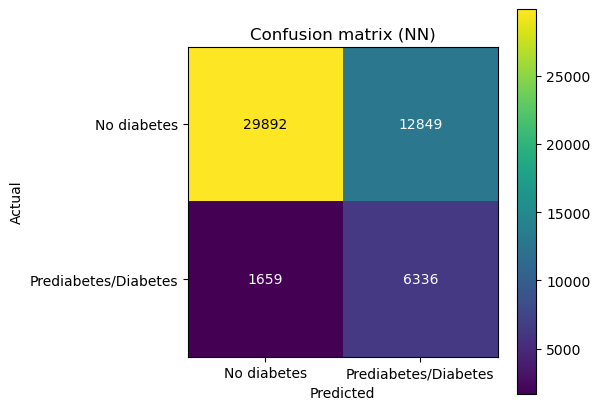

In [14]:
# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)

fig, ax = plt.subplots(figsize=(5, 5))
image = ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion matrix (NN)")

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] < cm.max() / 2 else "black")

plt.colorbar(image, ax=ax)
plt.show()

In [15]:
# Recall split by the ORIGINAL label: how many prediabetes vs diabetes cases does the model catch?
for c, name in [(1, 'Prediabetes (1)'), (2, 'Diabetes (2)')]:
    mask = y012_test == c
    recall_c = np.mean(test_predictions[mask] == 1)
    print(f'{name:16s}: {mask.sum():5d} people in test set, caught {recall_c:.1%}')

Prediabetes (1) :   906 people in test set, caught 64.9%
Diabetes (2)    :  7089 people in test set, caught 81.1%


## Prediction functions for explainability

In [16]:
# Binary (0/1) features are treated as categorical by LIME
cat_cols = [c for c in FEATURE_COLS
            if set(np.unique(X_train_raw[:, FEATURE_COLS.index(c)])) <= {0.0, 1.0}]
num_cols = [c for c in FEATURE_COLS if c not in cat_cols]
cat_indices = [FEATURE_COLS.index(c) for c in cat_cols]

print('Categorical (binary):', cat_cols)
print('Numerical / ordinal :', num_cols)

Categorical (binary): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Numerical / ordinal : ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']


In [17]:
def predict_proba(X_raw_array):
    X_scaled = scaler.transform(np.asarray(X_raw_array, dtype=np.float32)).astype(np.float32)
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(torch.from_numpy(X_scaled))).numpy().ravel()
    return np.column_stack([1 - p, p])

def predict(X_raw_array):
    return (predict_proba(X_raw_array)[:, 1] >= 0.5).astype(int)

test_proba = predict_proba(X_test_raw)[:, 1]
test_pred = predict(X_test_raw)

print(f'Test accuracy: {accuracy_score(y_test, test_pred):.3f}')
print(f'ROC-AUC:       {roc_auc_score(y_test, test_proba):.3f}')

Test accuracy: 0.714
ROC-AUC:       0.824


## 4. LIME explainer

In [18]:
import lime
import lime.lime_tabular

# Readable names for the binary features (0 = No, 1 = Yes; for Sex: 0 = female, 1 = male)
categorical_names = {}
for col in cat_cols:
    col_idx = FEATURE_COLS.index(col)
    if col == 'Sex':
        categorical_names[col_idx] = ['Female', 'Male']
    else:
        categorical_names[col_idx] = ['No', 'Yes']

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_raw,
    feature_names=FEATURE_COLS,
    class_names=class_names,
    categorical_features=cat_indices,
    categorical_names=categorical_names,
    mode='classification',
    random_state=42,
)
print('Explainer ready.')

Explainer ready.


## 5. LIME: single prediction

In [19]:
# Pick the first test instance predicted as positive (prediabetes/diabetes)
diabetes_mask = test_pred == pos_label
idx = np.where(diabetes_mask)[0][0]

instance = X_test_raw[idx]
pred_proba = predict_proba(instance.reshape(1, -1))[0]
pred_class = class_names[int(pred_proba.argmax())]

print(f'Explaining instance index {idx}')
print(f'Predicted class : {pred_class}   (true class: {class_names[int(y_test[idx])]}, Diabetes_012 = {y012_test[idx]})')
print(f'Class probabilities: {dict(zip(class_names, pred_proba.round(3)))}')
pd.Series(instance, index=FEATURE_COLS).to_frame('value').T

Explaining instance index 0
Predicted class : Prediabetes/Diabetes   (true class: No diabetes, Diabetes_012 = 0)
Class probabilities: {'No diabetes': np.float32(0.326), 'Prediabetes/Diabetes': np.float32(0.674)}


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
value,1.0,0.0,1.0,31.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,0.0,9.0,4.0,5.0


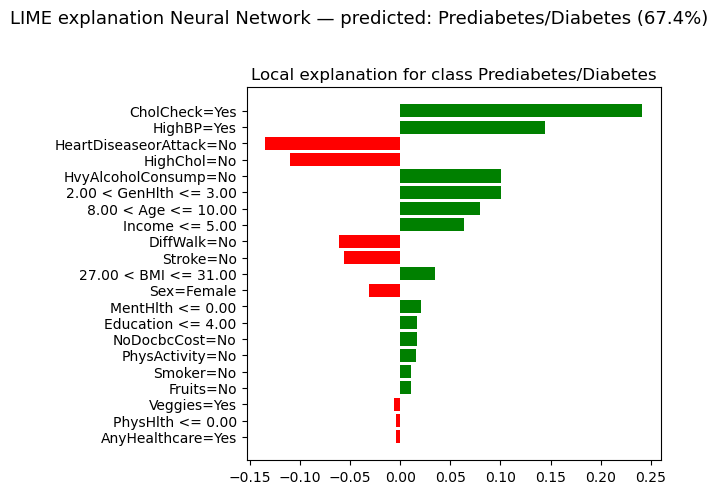

In [20]:
exp = explainer.explain_instance(
    data_row=instance,
    predict_fn=predict_proba,
    num_features=len(FEATURE_COLS),   # all 21 features in the explanation
    num_samples=5000,                 # neighbourhood samples for the surrogate
)

fig = exp.as_pyplot_figure(label=pos_label)
fig.suptitle(f'LIME explanation Neural Network — predicted: {pred_class} ({pred_proba.max():.1%})',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [21]:
# Also inspect the raw weights as a DataFrame
weights = exp.as_list(label=pos_label)
pd.DataFrame(weights, columns=['feature condition', 'LIME weight']).sort_values(
    'LIME weight', key=abs, ascending=False
)

,feature condition,LIME weight
0,CholCheck=Yes,0.241309
1,HighBP=Yes,0.144238
2,HeartDiseaseorAttack=No,-0.134721
3,HighChol=No,-0.110337
4,HvyAlcoholConsump=No,0.100722
5,2.00 < GenHlth <= 3.00,0.100528
6,8.00 < Age <= 10.00,0.079153
7,Income <= 5.00,0.063637
8,DiffWalk=No,-0.061454
9,Stroke=No,-0.056216


## 6. LIME: no-diabetes prediction

Explaining instance index 22 (true class: No diabetes)


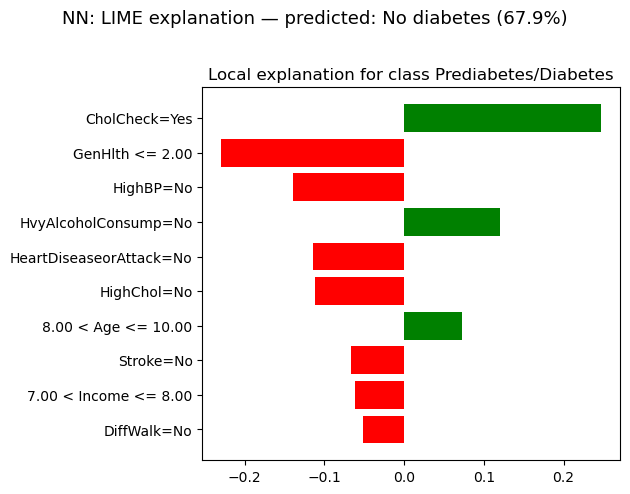

In [22]:
no_diabetes_mask = test_pred == 0
idx2 = np.where(no_diabetes_mask)[0][15]

instance2 = X_test_raw[idx2]
pred_proba2 = predict_proba(instance2.reshape(1, -1))[0]
pred_class2 = class_names[int(pred_proba2.argmax())]

exp2 = explainer.explain_instance(
    data_row=instance2,
    predict_fn=predict_proba,
    num_features=10,
    num_samples=5000,
)

print(f'Explaining instance index {idx2} (true class: {class_names[int(y_test[idx2])]})')
fig2 = exp2.as_pyplot_figure(label=pos_label)
fig2.suptitle(f'NN: LIME explanation — predicted: {pred_class2} ({pred_proba2.max():.1%})',
              fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 7. LIME: stability across seeds

In [23]:
from collections import Counter

N_RUNS = 10
top_k = 5

feature_counts = Counter()
for run_seed in range(N_RUNS):
    local_exp = lime.lime_tabular.LimeTabularExplainer(
        training_data=X_train_raw,
        feature_names=FEATURE_COLS,
        class_names=class_names,
        categorical_features=cat_indices,
        categorical_names=categorical_names,
        mode='classification',
        random_state=run_seed,
    ).explain_instance(
        data_row=instance,
        predict_fn=predict_proba,
        num_features=top_k,
        num_samples=5000,
    )
    for feat_name, _ in local_exp.as_list(label=pos_label):
        feature_counts[feat_name] += 1

stability_df = pd.DataFrame(
    feature_counts.most_common(), columns=['feature condition', f'appearances (/{N_RUNS})']
)
print(stability_df.to_string(index=False))

      feature condition  appearances (/10)
          CholCheck=Yes                 10
             HighBP=Yes                 10
            HighChol=No                 10
 2.00 < GenHlth <= 3.00                 10
HeartDiseaseorAttack=No                  9
    8.00 < Age <= 10.00                  1


## 8. LIME: aggregated weights (global view)

In [24]:
N_EXPLAIN = 100  # increase for smoother averages (slower)
rng = np.random.default_rng(0)
sample_idx = rng.choice(len(X_test_raw), size=N_EXPLAIN, replace=False)

weight_accumulator = {f: [] for f in FEATURE_COLS}

for i in sample_idx:
    e = explainer.explain_instance(
        data_row=X_test_raw[i],
        predict_fn=predict_proba,
        num_features=len(FEATURE_COLS),
        num_samples=1000,   # fewer samples: faster but noisier
    )
    for feat_idx, w in e.as_map()[pos_label]:
        weight_accumulator[FEATURE_COLS[feat_idx]].append(w)

mean_abs_weight = {}
for f, ws in weight_accumulator.items():
    if ws:
        mean_abs_weight[f] = np.mean(np.abs(ws))

global_df = pd.DataFrame(
    sorted(mean_abs_weight.items(), key=lambda x: x[1], reverse=True),
    columns=['feature', 'mean |LIME weight|']
)
print(global_df.to_string(index=False))

             feature  mean |LIME weight|
           CholCheck            0.225660
             GenHlth            0.196009
              HighBP            0.137077
   HvyAlcoholConsump            0.119626
HeartDiseaseorAttack            0.117112
                 BMI            0.109820
            HighChol            0.107342
                 Age            0.102723
              Stroke            0.060488
            DiffWalk            0.050604
              Income            0.045745
                 Sex            0.029661
            MentHlth            0.021006
       AnyHealthcare            0.016536
           Education            0.015825
             Veggies            0.014538
         NoDocbcCost            0.013330
              Smoker            0.012780
        PhysActivity            0.010791
            PhysHlth            0.008731
              Fruits            0.008129


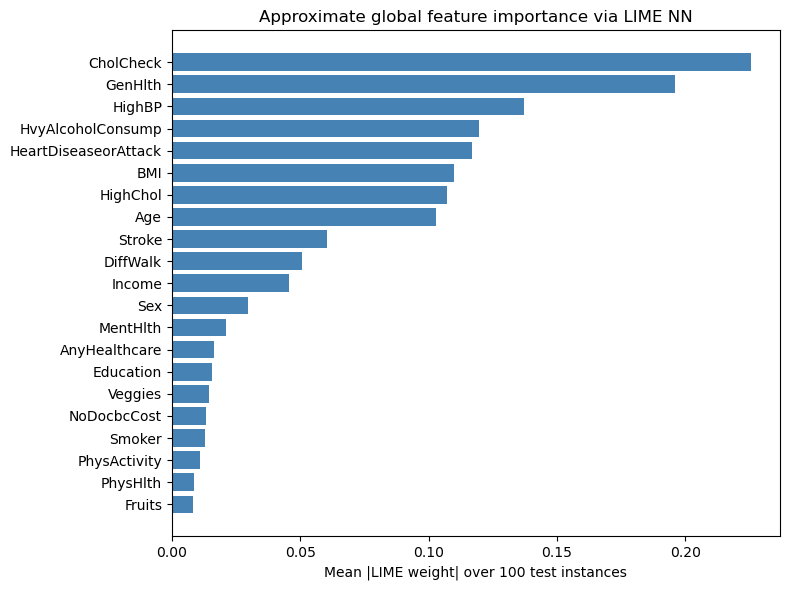

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(global_df['feature'][::-1], global_df['mean |LIME weight|'][::-1], color='steelblue')
ax.set_xlabel(f'Mean |LIME weight| over {N_EXPLAIN} test instances')
ax.set_title('Approximate global feature importance via LIME NN')
plt.tight_layout()
plt.show()

## 9. SHAP (DeepExplainer)

In [26]:
import shap

# Explain the probability output: logits -> sigmoid
prob_model = nn.Sequential(model, nn.Sigmoid()).eval()

# Background (reference) data: a random sample of the scaled training data
N_BACKGROUND = 200
rng_bg = np.random.default_rng(SEED)
bg_idx = rng_bg.choice(len(X_train), size=N_BACKGROUND, replace=False)
background = torch.tensor(X_train[bg_idx], dtype=torch.float32)

deep_explainer = shap.DeepExplainer(prob_model, background)

def to_2d(shap_vals):
    # DeepExplainer returns a list, a 2-D or a 3-D array depending on the shap version
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]
    shap_vals = np.asarray(shap_vals)
    if shap_vals.ndim == 3:
        shap_vals = shap_vals[:, :, 0]
    return shap_vals

# SHAP values for a 500-instance sample of the test set
N_SHAP = 500
sv_pos_all = to_2d(deep_explainer.shap_values(torch.tensor(X_test[:N_SHAP])))

expected_val = float(np.ravel(np.asarray(deep_explainer.expected_value))[0])

print(f'SHAP values shape : {sv_pos_all.shape}')
print(f'Baseline (E[f(X)]): {expected_val:.4f}')

SHAP values shape : (500, 21)
Baseline (E[f(X)]): 0.3698


In [27]:
# Check the efficiency property: baseline + sum of SHAP values ≈ predicted probability
f_x = predict_proba(X_test_raw[:N_SHAP])[:, 1]
reconstructed = expected_val + sv_pos_all.sum(axis=1)
print(f'Max |f(x) − (E[f(X)] + Σ SHAP)| over {N_SHAP} instances: {np.max(np.abs(f_x - reconstructed)):.2e}')

Max |f(x) − (E[f(X)] + Σ SHAP)| over 500 instances: 2.03e-07


### 9.1 SHAP: single instances

Instance predicted as: Prediabetes/Diabetes (67.4%)


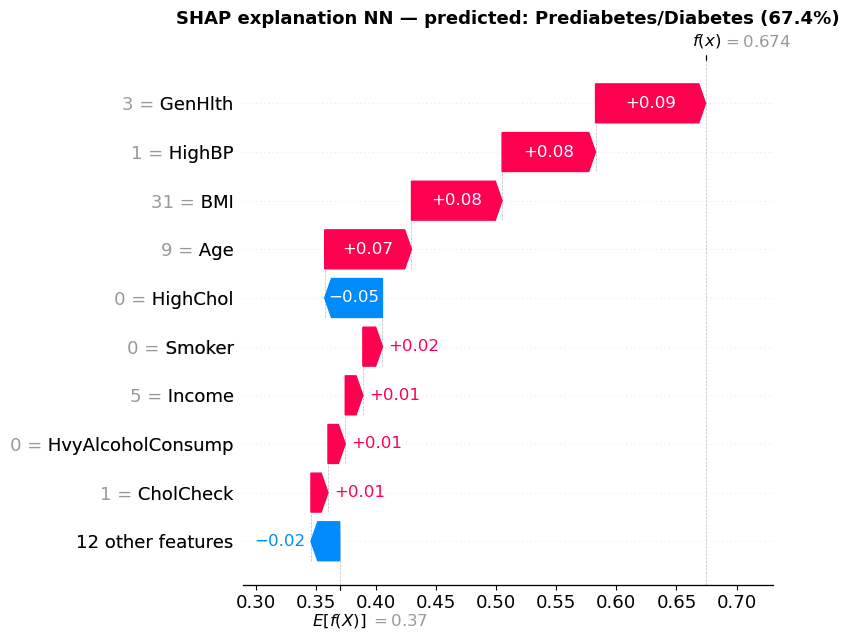

In [28]:
sv_hi_pos = to_2d(deep_explainer.shap_values(torch.tensor(X_test[idx:idx + 1])))[0]

shap_exp_hi = shap.Explanation(
    values=sv_hi_pos,
    base_values=expected_val,
    data=instance,
    feature_names=FEATURE_COLS,
)
print(f'Instance predicted as: {pred_class} ({pred_proba.max():.1%})')
shap.plots.waterfall(shap_exp_hi, show=False)
plt.title(f'SHAP explanation NN — predicted: {pred_class} ({pred_proba.max():.1%})',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Instance predicted as: No diabetes (67.9%)


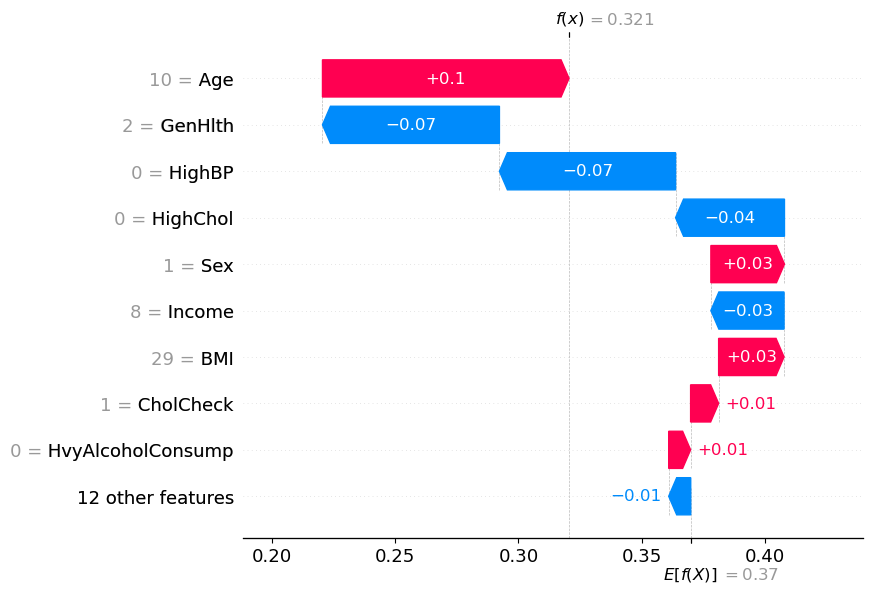

In [29]:
sv_lo_pos = to_2d(deep_explainer.shap_values(torch.tensor(X_test[idx2:idx2 + 1])))[0]

shap_exp_lo = shap.Explanation(
    values=sv_lo_pos,
    base_values=expected_val,
    data=instance2,
    feature_names=FEATURE_COLS,
)
print(f'Instance predicted as: {pred_class2} ({pred_proba2.max():.1%})')
shap.plots.waterfall(shap_exp_lo)

### 9.2 SHAP: global importance

/var/folders/fs/mwdr9m3n0tg_c48y2sp0j4l40000gn/T/ipykernel_51254/256524370.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_pos_all, X_test_raw[:N_SHAP], feature_names=FEATURE_COLS)


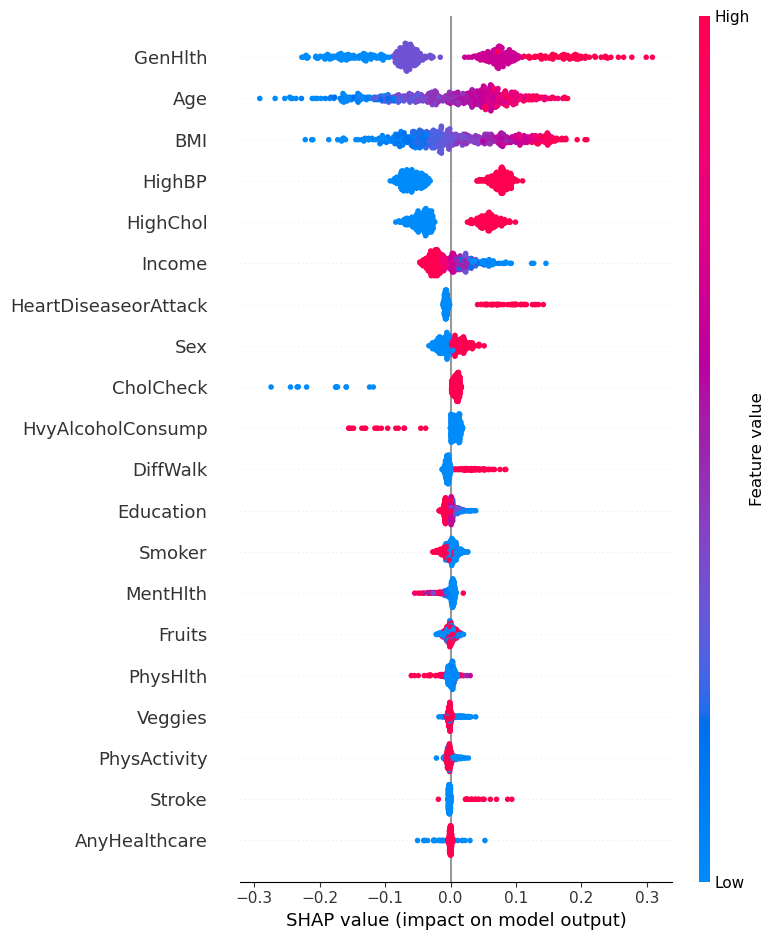

In [30]:
shap.summary_plot(sv_pos_all, X_test_raw[:N_SHAP], feature_names=FEATURE_COLS)

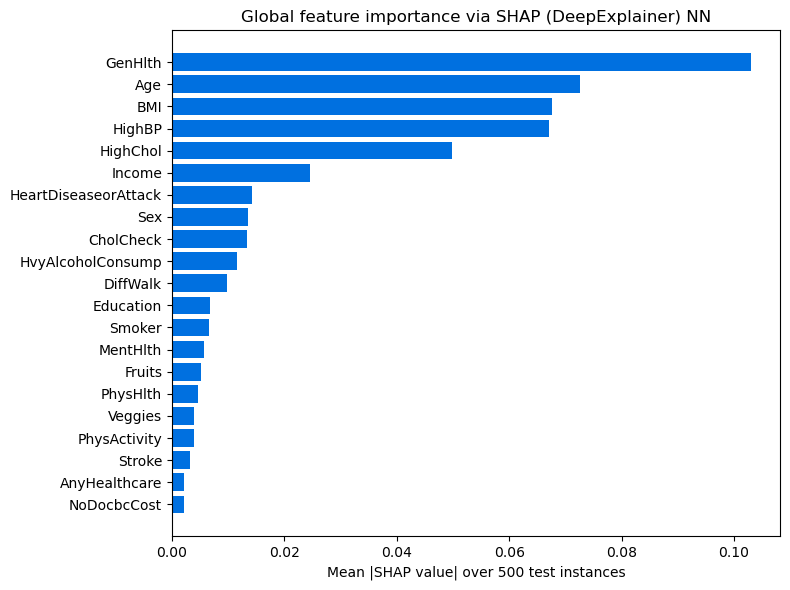

             feature  mean |SHAP|
             GenHlth     0.103034
                 Age     0.072539
                 BMI     0.067664
              HighBP     0.067178
            HighChol     0.049893
              Income     0.024657
HeartDiseaseorAttack     0.014267
                 Sex     0.013490
           CholCheck     0.013436
   HvyAlcoholConsump     0.011599
            DiffWalk     0.009801
           Education     0.006704
              Smoker     0.006570
            MentHlth     0.005677
              Fruits     0.005131
            PhysHlth     0.004666
             Veggies     0.004002
        PhysActivity     0.003855
              Stroke     0.003181
       AnyHealthcare     0.002114
         NoDocbcCost     0.002104


In [31]:
mean_abs_shap = np.mean(np.abs(sv_pos_all), axis=0)
shap_global_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'mean |SHAP|': mean_abs_shap,
}).sort_values('mean |SHAP|', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(shap_global_df['feature'][::-1], shap_global_df['mean |SHAP|'][::-1], color="#0070e0")
ax.set_xlabel(f'Mean |SHAP value| over {N_SHAP} test instances')
ax.set_title('Global feature importance via SHAP (DeepExplainer) NN')
plt.tight_layout()
plt.show()
print(shap_global_df.to_string(index=False))

## 10. LIME vs SHAP
### 10.1 Same instance

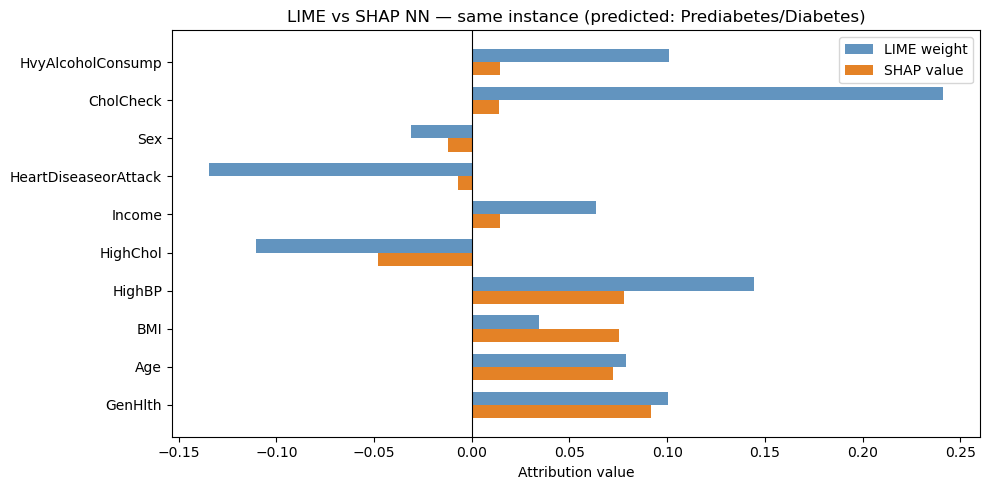

In [32]:
# LIME weights for the positive instance -> map to feature names
lime_by_feature = {FEATURE_COLS[i]: w for i, w in exp.as_map()[pos_label]}

# SHAP values for the same instance
shap_by_feature = dict(zip(FEATURE_COLS, sv_hi_pos))

# Compare over the top-10 features by mean |SHAP| (global ranking)
top10 = shap_global_df['feature'].head(10).tolist()
lime_local = [lime_by_feature.get(f, 0) for f in top10]
shap_local = [shap_by_feature[f] for f in top10]

x = np.arange(len(top10))
bar_w = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(x + bar_w/2, lime_local, bar_w, label='LIME weight', color='steelblue', alpha=0.85)
ax.barh(x - bar_w/2, shap_local, bar_w, label='SHAP value', color='#e06c00', alpha=0.85)
ax.set_yticks(x)
ax.set_yticklabels(top10)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Attribution value')
ax.set_title(f'LIME vs SHAP NN — same instance (predicted: {pred_class})')
ax.legend()
plt.tight_layout()
plt.show()

### 10.2 Global ranking

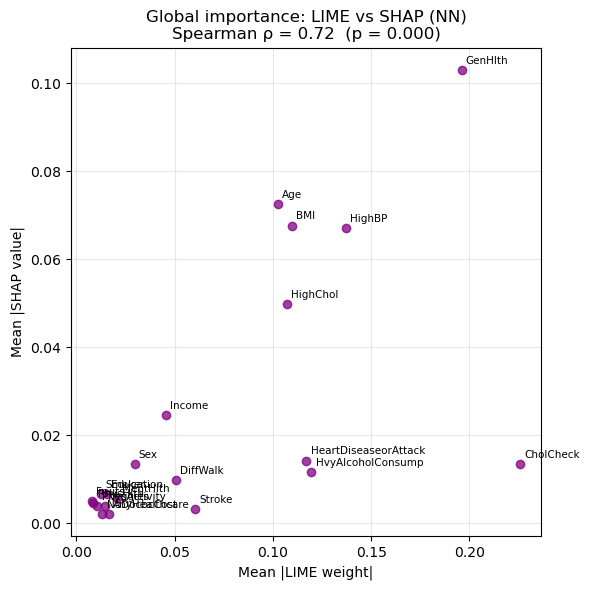

Spearman rank correlation: ρ = 0.716,  p = 0.0003


In [33]:
from scipy.stats import spearmanr

# Align global rankings by feature name
lime_series = global_df.set_index('feature')['mean |LIME weight|']
shap_series = shap_global_df.set_index('feature')['mean |SHAP|']
aligned = pd.DataFrame({'LIME': lime_series, 'SHAP': shap_series}).dropna()

rho, pval = spearmanr(aligned['LIME'], aligned['SHAP'])

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(aligned['LIME'], aligned['SHAP'], color='purple', alpha=0.75, zorder=3)
for feat, row in aligned.iterrows():
    ax.annotate(feat, (row['LIME'], row['SHAP']), fontsize=7.5, ha='left', va='bottom',
                xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('Mean |LIME weight|')
ax.set_ylabel('Mean |SHAP value|')
ax.set_title(f'Global importance: LIME vs SHAP ({MODEL_TAG})\nSpearman ρ = {rho:.2f}  (p = {pval:.3f})')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Spearman rank correlation: ρ = {rho:.3f},  p = {pval:.4f}')

### 10.3 Fidelity

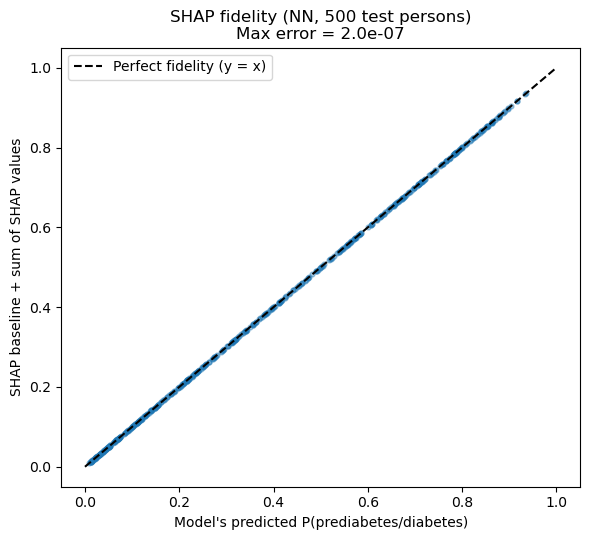

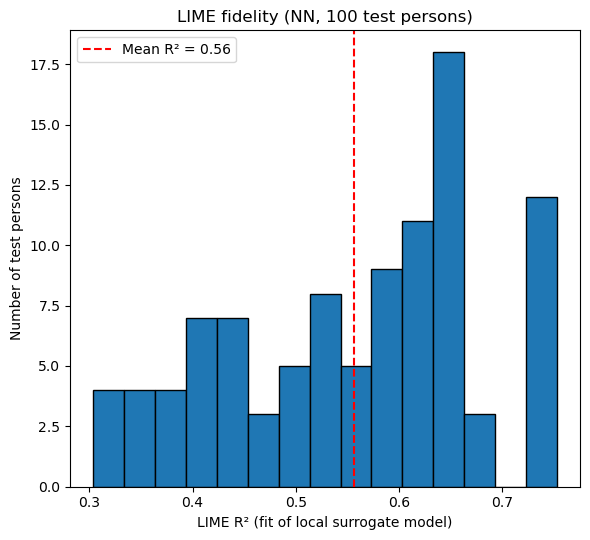

SHAP max error: 2.0e-07
LIME mean R²:   0.56  (min 0.30, max 0.75)


In [34]:
# ===== Fidelity: SHAP vs LIME =====

# --- Plot 1: SHAP additivity (uses f_x and reconstructed from section 9) ---
max_err = np.max(np.abs(f_x - reconstructed))

plt.figure(figsize=(6, 5.5))
plt.scatter(f_x, reconstructed, alpha=0.4, s=12)
plt.plot([0, 1], [0, 1], 'k--', label='Perfect fidelity (y = x)')
plt.xlabel("Model's predicted P(prediabetes/diabetes)")
plt.ylabel('SHAP baseline + sum of SHAP values')
plt.title(f'SHAP fidelity (NN, {N_SHAP} test persons)\nMax error = {max_err:.1e}')
plt.legend()
plt.tight_layout()
plt.savefig('fidelity_shap_nn.png', dpi=200)
plt.show()

# --- Plot 2: LIME R² across test persons ---
lime_r2 = []
for i in sample_idx:                  # same 100 test persons as section 8
    e = explainer.explain_instance(
        data_row=X_test_raw[i],
        predict_fn=predict_proba,
        num_features=len(FEATURE_COLS),
        num_samples=5000,
    )
    lime_r2.append(e.score)           # R² of LIME's local linear model

lime_r2 = np.array(lime_r2)

plt.figure(figsize=(6, 5.5))
plt.hist(lime_r2, bins=15, edgecolor='black')
plt.axvline(lime_r2.mean(), color='red', linestyle='--',
            label=f'Mean R² = {lime_r2.mean():.2f}')
plt.xlabel('LIME R² (fit of local surrogate model)')
plt.ylabel('Number of test persons')
plt.title(f'LIME fidelity (NN, {len(lime_r2)} test persons)')
plt.legend()
plt.tight_layout()
plt.savefig('fidelity_lime_nn.png', dpi=200)
plt.show()

print(f'SHAP max error: {max_err:.1e}')
print(f'LIME mean R²:   {lime_r2.mean():.2f}  (min {lime_r2.min():.2f}, max {lime_r2.max():.2f})')

### 10.4 False negative vs true positive

People with prediabetes/diabetes in test set: 7995
  Found (true positives):   6336
  Missed (false negatives): 1659

                      False negative (#22542)  True positive (#13238)
HighBP                                    0.0                     1.0
HighChol                                  0.0                     0.0
CholCheck                                 1.0                     1.0
BMI                                      20.0                    44.0
Smoker                                    0.0                     0.0
Stroke                                    0.0                     0.0
HeartDiseaseorAttack                      0.0                     0.0
PhysActivity                              1.0                     0.0
Fruits                                    1.0                     0.0
Veggies                                   1.0                     0.0
HvyAlcoholConsump                         0.0                     0.0
AnyHealthcare                             

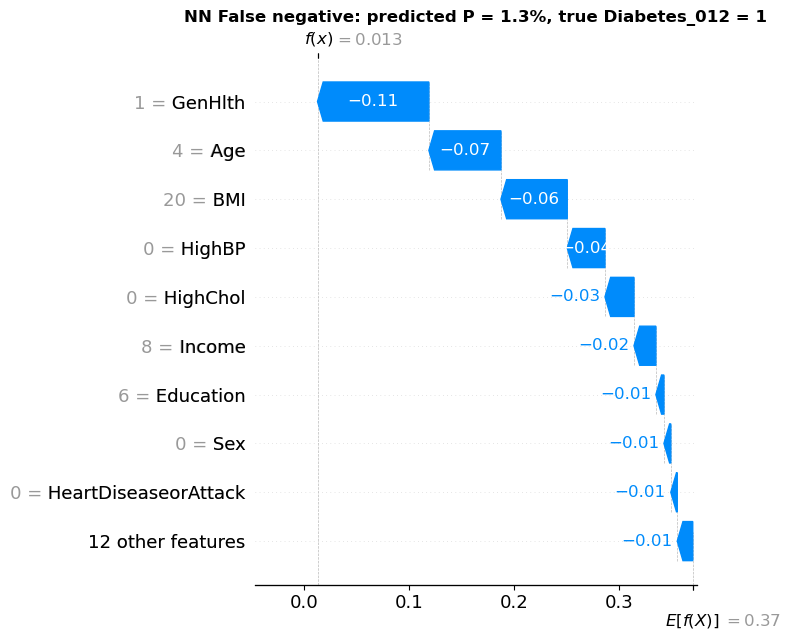

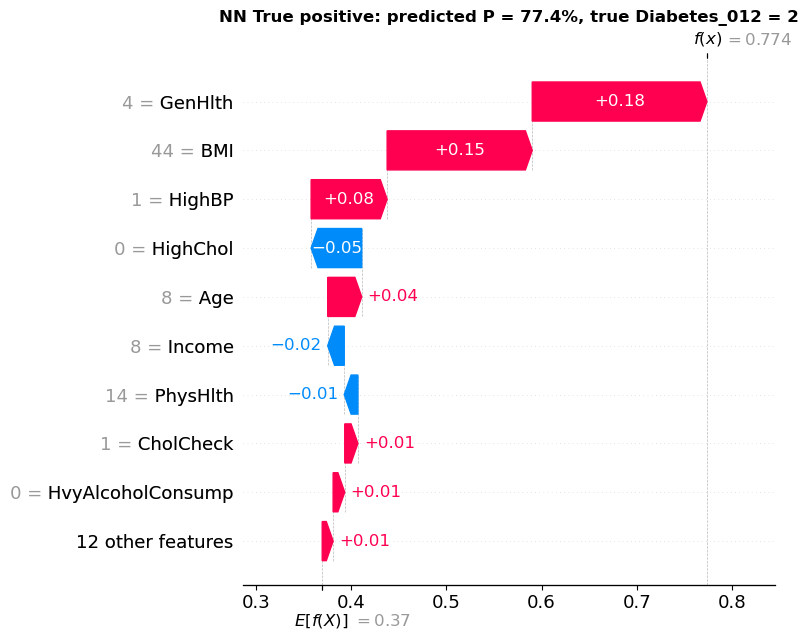

In [35]:
# ===== Local SHAP: false negative vs true positive =====

# People who HAVE prediabetes/diabetes, split by whether the model caught them
fn_idx = np.where((test_pred == 0) & (y_test == 1))[0]   # missed
tp_idx = np.where((test_pred == 1) & (y_test == 1))[0]   # found
print(f'People with prediabetes/diabetes in test set: {int(np.sum(y_test == 1))}')
print(f'  Found (true positives):   {len(tp_idx)}')
print(f'  Missed (false negatives): {len(fn_idx)}\n')

# False negative: the most confident miss (lowest predicted risk)
idx_fn = fn_idx[np.argmin(test_proba[fn_idx])]

# True positive: a typical hit (predicted risk closest to the median of all hits)
median_tp = np.median(test_proba[tp_idx])
idx_tp = tp_idx[np.argmin(np.abs(test_proba[tp_idx] - median_tp))]

# Feature values side by side
cases = pd.DataFrame({
    f'False negative (#{idx_fn})': X_test_raw[idx_fn],
    f'True positive (#{idx_tp})': X_test_raw[idx_tp],
}, index=FEATURE_COLS)
print(cases.to_string())

# SHAP waterfall for each case
for name, i in [('False negative', idx_fn), ('True positive', idx_tp)]:
    sv_i = to_2d(deep_explainer.shap_values(torch.tensor(X_test[i:i + 1])))[0]
    exp_i = shap.Explanation(values=sv_i, base_values=expected_val,
                             data=X_test_raw[i], feature_names=FEATURE_COLS)
    shap.plots.waterfall(exp_i, max_display=10, show=False)
    plt.title(f'NN {name}: predicted P = {test_proba[i]:.1%}, true Diabetes_012 = {y012_test[i]}',
              fontsize=12, fontweight='bold')
    plt.tight_layout()
    file_name = 'shap_' + name.lower().replace(' ', '_') + '_nn.png'
    plt.savefig(file_name, dpi=200, bbox_inches='tight')
    plt.show()

## 11. Latent space: PCA, t-SNE and UMAP

### 11.1 Hidden-layer activations

In [36]:
# model.network = [Linear(21,32), ReLU, Linear(32,16), ReLU, Linear(16,1)]
# model.network[:4] stops after the second ReLU -> one 16-dimensional vector per person
LATENT_NAME = 'last hidden layer (16 units)'

N_LATENT = 5000   # t-SNE and UMAP are slow on the full test set, so we use a random sample
rng_lat = np.random.default_rng(SEED)
lat_idx = rng_lat.choice(len(X_test), size=N_LATENT, replace=False)

model.eval()
with torch.no_grad():
    H = model.network[:4](torch.tensor(X_test[lat_idx])).numpy()

lat_y012 = y012_test[lat_idx]     # true 3-class label of the sampled persons
lat_proba = test_proba[lat_idx]   # model's predicted probability

print('Hidden representation shape:', H.shape)
print('Hidden units that are 0 for every sampled person ("dead" ReLUs):', int(np.sum(H.max(axis=0) == 0)))
print('Classes in the sample (0, 1, 2):', np.bincount(lat_y012))

Hidden representation shape: (5000, 16)
Hidden units that are 0 for every sampled person ("dead" ReLUs): 1
Classes in the sample (0, 1, 2): [4232   92  676]


### 11.2 Compute the embeddings

In [37]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# --- PCA: linear projection onto the 2 directions with the most variance ---
pca = PCA(n_components=2, random_state=SEED)
emb_pca = pca.fit_transform(H)
print('PCA explained variance ratio (PC1, PC2):', pca.explained_variance_ratio_.round(3))

# --- t-SNE: non-linear, keeps local neighbourhoods ---
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED)
emb_tsne = tsne.fit_transform(H)
print('t-SNE done')

# --- UMAP: non-linear, keeps local neighbourhoods and (some) global structure ---
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED)
emb_umap = reducer.fit_transform(H)
print('UMAP done')

PCA explained variance ratio (PC1, PC2): [0.808 0.075]
t-SNE done


/Users/noahwestheimer/miniforge3/envs/dtu02451/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done


### 11.3 Coloured by label and prediction

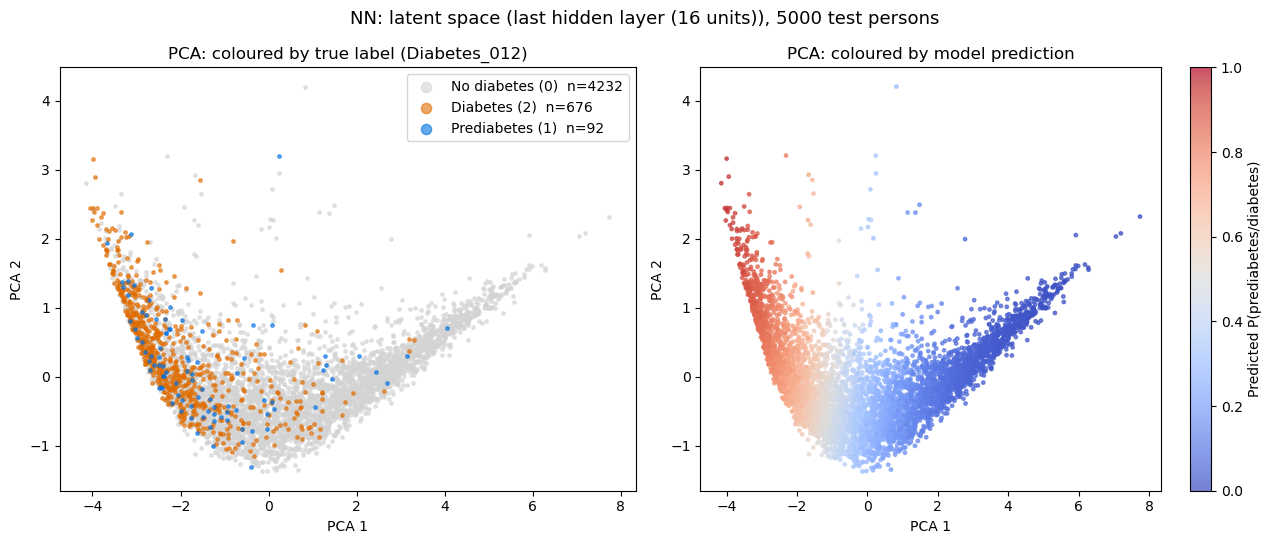

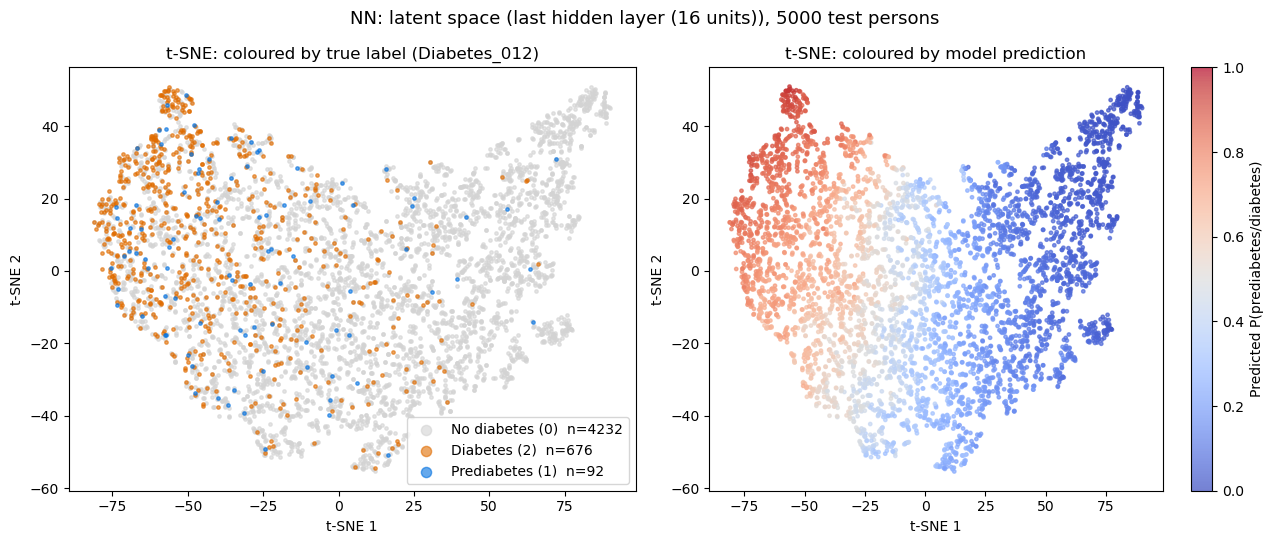

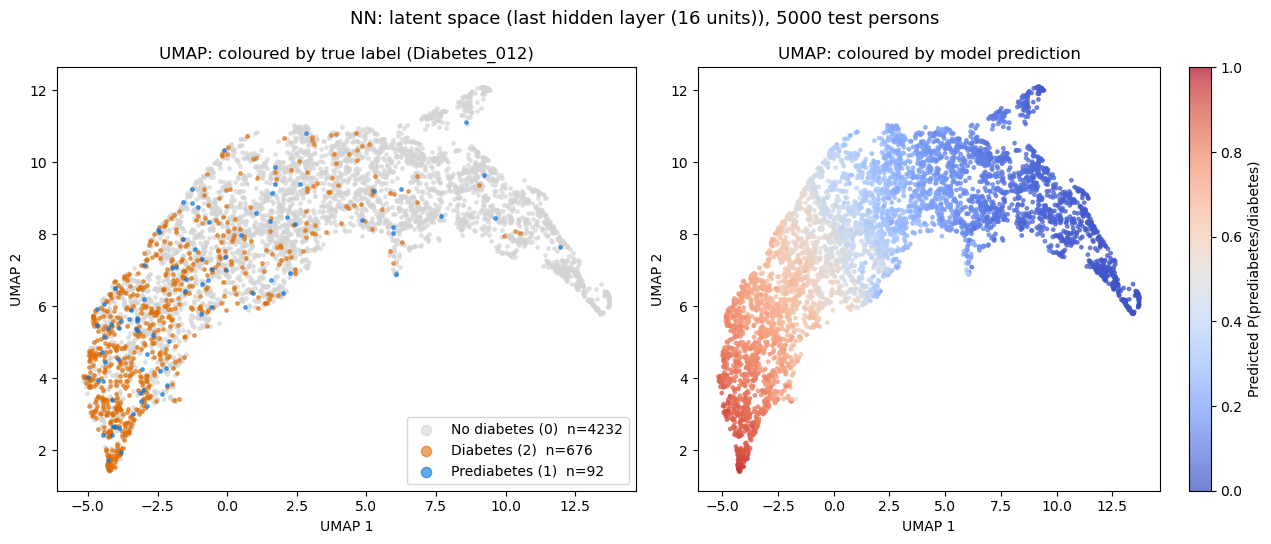

In [38]:
class_colors = {0: 'lightgray', 1: '#0070e0', 2: '#e06c00'}
class_labels = {0: 'No diabetes (0)', 1: 'Prediabetes (1)', 2: 'Diabetes (2)'}

embeddings = [(emb_pca, 'PCA'), (emb_tsne, 't-SNE'), (emb_umap, 'UMAP')]

for emb, method_name in embeddings:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

    # Left: true 3-class label. The big class is drawn first so the small classes stay visible on top.
    for c in [0, 2, 1]:
        mask = lat_y012 == c
        axes[0].scatter(emb[mask, 0], emb[mask, 1], s=6, alpha=0.6, color=class_colors[c],
                        label=f'{class_labels[c]}  n={mask.sum()}')
    axes[0].set_title(f'{method_name}: coloured by true label (Diabetes_012)')
    axes[0].legend(markerscale=3, loc='best')

    # Right: the model's predicted probability
    sc = axes[1].scatter(emb[:, 0], emb[:, 1], c=lat_proba, cmap='coolwarm', vmin=0, vmax=1, s=6, alpha=0.7)
    plt.colorbar(sc, ax=axes[1], label='Predicted P(prediabetes/diabetes)')
    axes[1].set_title(f'{method_name}: coloured by model prediction')

    for ax in axes:
        ax.set_xlabel(f'{method_name} 1')
        ax.set_ylabel(f'{method_name} 2')

    fig.suptitle(f'{MODEL_TAG}: latent space ({LATENT_NAME}), {N_LATENT} test persons', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'latent_{method_name.lower().replace("-", "")}_{MODEL_TAG.lower().replace(" ", "")}.png', dpi=200)
    plt.show()

### 11.4 Concepts in the latent space

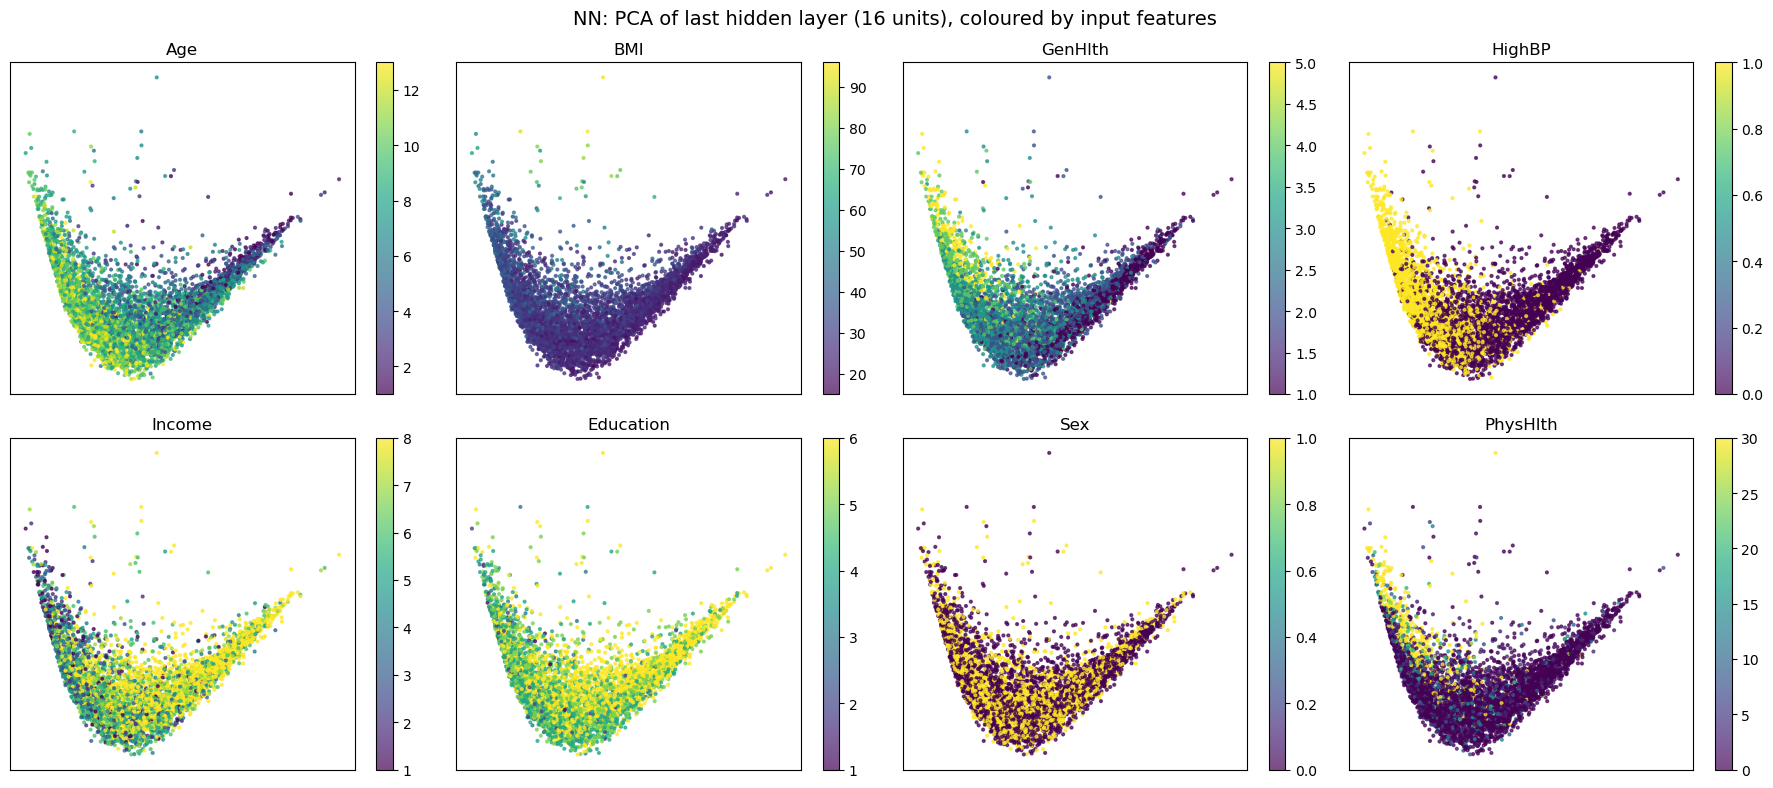

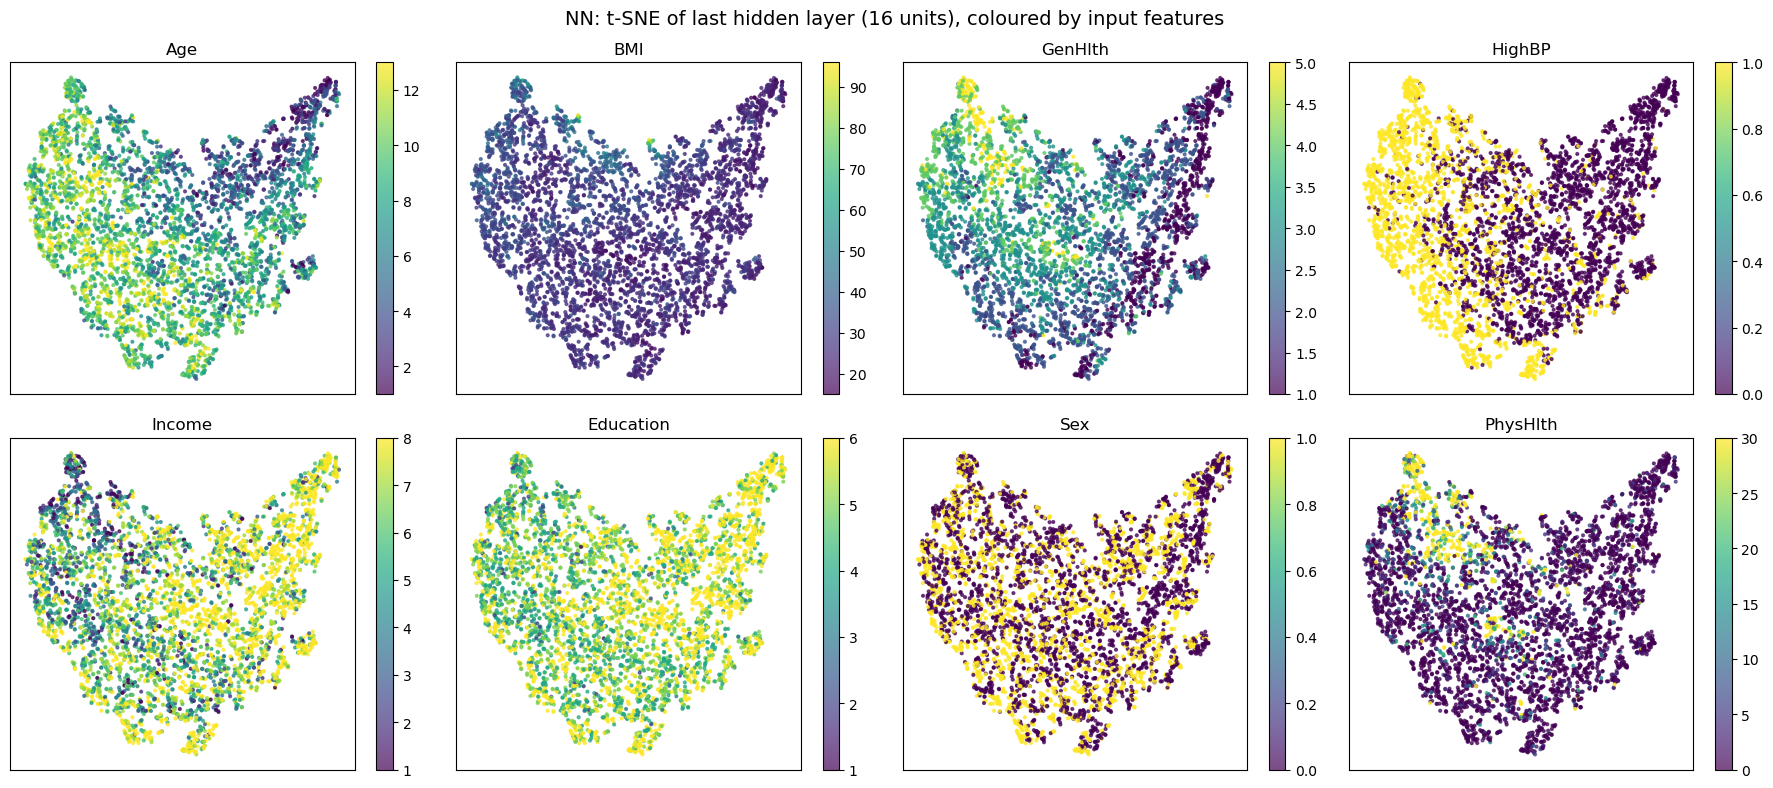

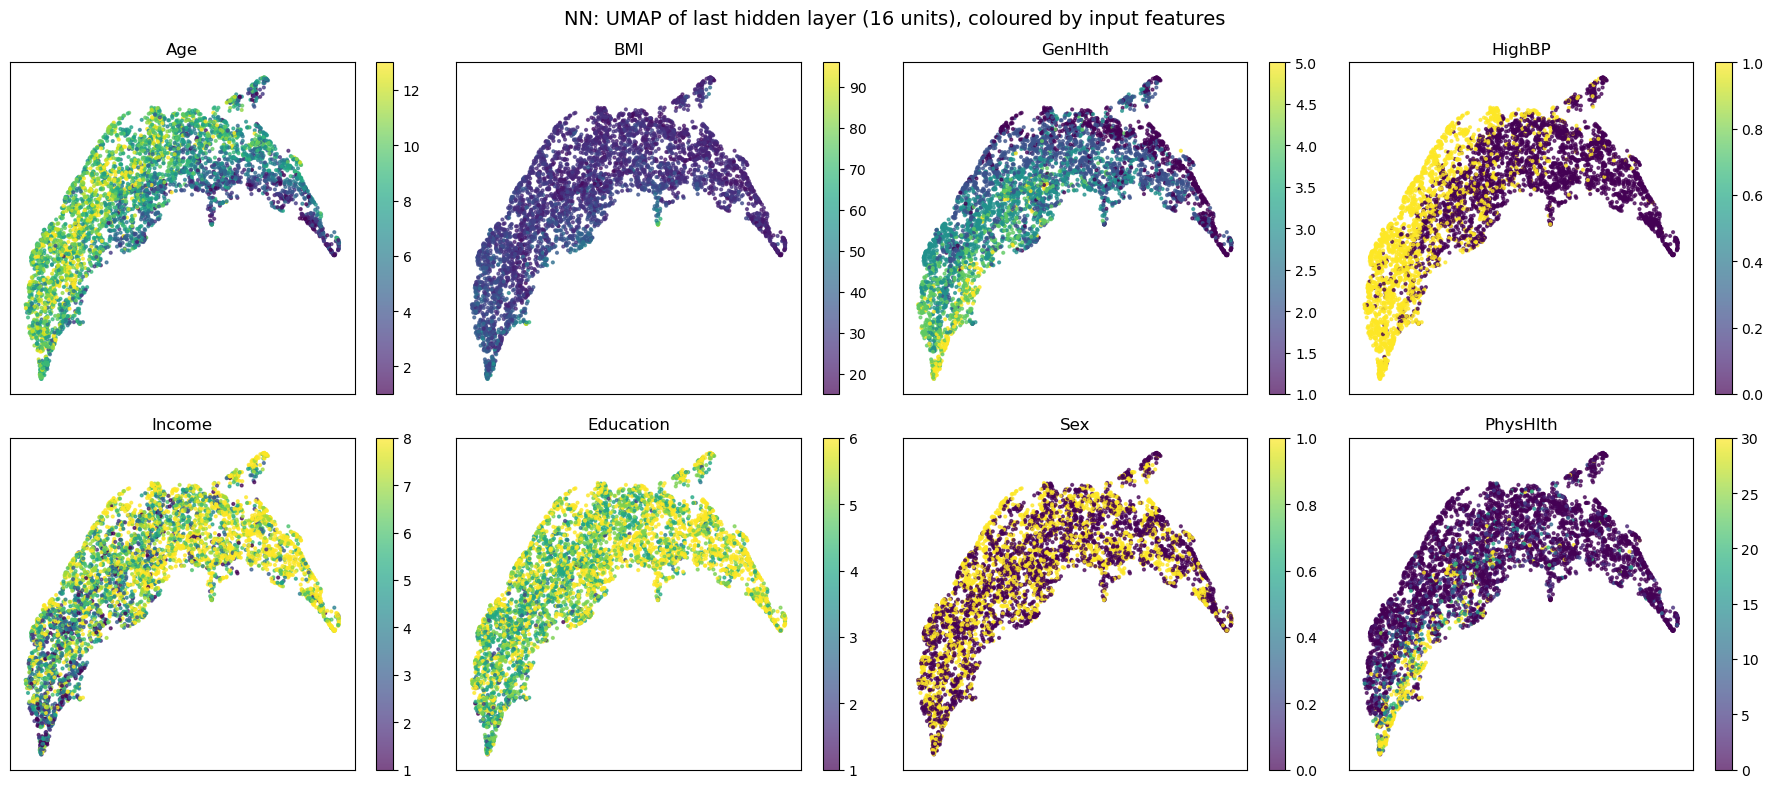

In [39]:
concept_features = ['Age', 'BMI', 'GenHlth', 'HighBP', 'Income', 'Education', 'Sex', 'PhysHlth']
lat_raw = X_test_raw[lat_idx]

for emb, method_name in embeddings:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, feat in zip(axes.ravel(), concept_features):
        values = lat_raw[:, FEATURE_COLS.index(feat)]
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, cmap='viridis', s=4, alpha=0.7)
        plt.colorbar(sc, ax=ax)
        ax.set_title(feat)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f'{MODEL_TAG}: {method_name} of {LATENT_NAME}, coloured by input features', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'latent_concepts_{method_name.lower().replace("-", "")}_{MODEL_TAG.lower().replace(" ", "")}.png', dpi=200)
    plt.show()

## 12. TCAV: concept *low income* (Income removed)

### 12.1 Data without Income

In [40]:
from sklearn.linear_model import LogisticRegression

# Position of the Income column in the original feature list
inc_idx = FEATURE_COLS.index('Income')
FEATURE_COLS_NI = [c for c in FEATURE_COLS if c != 'Income']

# Remove the Income column from the scaled data (same rows and same split as before).
# StandardScaler scales every column on its own, so deleting a scaled column gives
# exactly the same numbers as scaling the 20 remaining columns again.
X_train_ni = np.delete(X_train, inc_idx, axis=1)
X_val_ni = np.delete(X_val, inc_idx, axis=1)
X_test_ni = np.delete(X_test, inc_idx, axis=1)

# Keep each person's income on the side.
# It is NOT given to the model, it is only used to choose concept examples later.
income_train = X_train_raw[:, inc_idx]
income_test = X_test_raw[:, inc_idx]

print('Features used by the new model:', len(FEATURE_COLS_NI))
print('Train:', X_train_ni.shape, ' Val:', X_val_ni.shape, ' Test:', X_test_ni.shape)

Features used by the new model: 20
Train: (162355, 20)  Val: (40589, 20)  Test: (50736, 20)


### 12.2 Retrain without Income

In [41]:
torch.manual_seed(SEED)

X_train_ni_t = torch.tensor(X_train_ni, dtype=torch.float32)
X_val_ni_t = torch.tensor(X_val_ni, dtype=torch.float32)
X_test_ni_t = torch.tensor(X_test_ni, dtype=torch.float32)

train_loader_ni = DataLoader(TensorDataset(X_train_ni_t, y_train_t), batch_size=batch_size, shuffle=True)
val_loader_ni = DataLoader(TensorDataset(X_val_ni_t, y_val_t), batch_size=batch_size, shuffle=False)

model_ni = DiabetesNN(n_features=X_train_ni.shape[1])   # 20 inputs instead of 21
criterion_ni = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
optimizer_ni = torch.optim.Adam(model_ni.parameters(), lr=0.001)

max_epochs = 100
patience = 5

best_val_loss_ni = float("inf")
epochs_without_improvement = 0
best_state_ni = None
train_losses_ni = []
val_losses_ni = []

for epoch in range(max_epochs):

    # ----- Training -----
    model_ni.train()
    running_loss = 0.0
    total = 0
    for X_batch, y_batch in train_loader_ni:
        optimizer_ni.zero_grad()
        loss = criterion_ni(model_ni(X_batch), y_batch)
        loss.backward()
        optimizer_ni.step()
        running_loss += loss.item() * X_batch.size(0)
        total += y_batch.size(0)
    train_loss = running_loss / total

    # ----- Validation -----
    model_ni.eval()
    running_val_loss = 0.0
    total = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader_ni:
            loss = criterion_ni(model_ni(X_batch), y_batch)
            running_val_loss += loss.item() * X_batch.size(0)
            total += y_batch.size(0)
    val_loss = running_val_loss / total

    train_losses_ni.append(train_loss)
    val_losses_ni.append(val_loss)
    print(f"Epoch {epoch + 1:02d} | train loss: {train_loss:.4f} | val loss: {val_loss:.4f}")

    # ----- Early stopping -----
    if val_loss < best_val_loss_ni:
        best_val_loss_ni = val_loss
        best_state_ni = copy.deepcopy(model_ni.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

# Use the weights from the epoch with the lowest validation loss
model_ni.load_state_dict(best_state_ni)
model_ni.eval()

Epoch 01 | train loss: 0.8973 | val loss: 0.8642
Epoch 02 | train loss: 0.8673 | val loss: 0.8612
Epoch 03 | train loss: 0.8645 | val loss: 0.8603
Epoch 04 | train loss: 0.8628 | val loss: 0.8599
Epoch 05 | train loss: 0.8618 | val loss: 0.8612
Epoch 06 | train loss: 0.8610 | val loss: 0.8602
Epoch 07 | train loss: 0.8604 | val loss: 0.8592
Epoch 08 | train loss: 0.8596 | val loss: 0.8591
Epoch 09 | train loss: 0.8591 | val loss: 0.8612
Epoch 10 | train loss: 0.8585 | val loss: 0.8600
Epoch 11 | train loss: 0.8583 | val loss: 0.8595
Epoch 12 | train loss: 0.8580 | val loss: 0.8587
Epoch 13 | train loss: 0.8574 | val loss: 0.8600
Epoch 14 | train loss: 0.8572 | val loss: 0.8584
Epoch 15 | train loss: 0.8568 | val loss: 0.8608
Epoch 16 | train loss: 0.8564 | val loss: 0.8598
Epoch 17 | train loss: 0.8560 | val loss: 0.8591
Epoch 18 | train loss: 0.8560 | val loss: 0.8588
Epoch 19 | train loss: 0.8555 | val loss: 0.8593
Early stopping at epoch 19


DiabetesNN(
  (network): Sequential(
    (0): Linear(in_features=20, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)

### 12.3 Performance with vs without Income

In [42]:
model.eval()
model_ni.eval()
with torch.no_grad():
    proba_full = torch.sigmoid(model(X_test_t)).numpy().ravel()        # original model (21 features)
    proba_ni = torch.sigmoid(model_ni(X_test_ni_t)).numpy().ravel()    # new model (20 features)

rows = []
for name, p in [('With Income (original)', proba_full), ('Without Income', proba_ni)]:
    pred = (p >= 0.5).astype(int)
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'balanced acc': balanced_accuracy_score(y_test, pred),
        'recall (pos)': np.mean(pred[y_test == 1] == 1),
        'ROC-AUC': roc_auc_score(y_test, p),
        'PR-AUC': average_precision_score(y_test, p),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

                 model  accuracy  balanced acc  recall (pos)  ROC-AUC  PR-AUC
With Income (original)     0.714         0.746         0.792    0.824    0.46
        Without Income     0.708         0.746         0.803    0.823    0.46


### 12.4 Predicted risk by income group

 Income  true rate  mean risk (with Income)  mean risk (without Income)
      1      0.287                    0.574                       0.538
      2      0.293                    0.595                       0.568
      3      0.262                    0.551                       0.530
      4      0.223                    0.509                       0.495
      5      0.196                    0.471                       0.465
      6      0.157                    0.419                       0.421
      7      0.141                    0.362                       0.373
      8      0.090                    0.271                       0.288


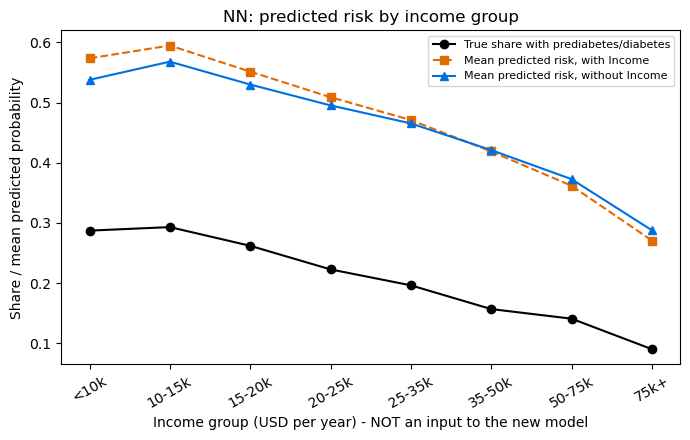

In [43]:
income_levels = np.arange(1, 9)
true_rate = []
mean_risk_full = []
mean_risk_ni = []
for level in income_levels:
    mask = income_test == level
    true_rate.append(np.mean(y_test[mask]))
    mean_risk_full.append(np.mean(proba_full[mask]))
    mean_risk_ni.append(np.mean(proba_ni[mask]))

print(pd.DataFrame({'Income': income_levels, 'true rate': true_rate,
                    'mean risk (with Income)': mean_risk_full,
                    'mean risk (without Income)': mean_risk_ni}).round(3).to_string(index=False))

plt.figure(figsize=(7, 4.5))
plt.plot(income_levels, true_rate, 'o-', color='black', label='True share with prediabetes/diabetes')
plt.plot(income_levels, mean_risk_full, 's--', color='#e06c00', label='Mean predicted risk, with Income')
plt.plot(income_levels, mean_risk_ni, '^-', color='#0070e0', label='Mean predicted risk, without Income')
plt.xticks(income_levels, ['<10k', '10-15k', '15-20k', '20-25k', '25-35k', '35-50k', '50-75k', '75k+'], rotation=30)
plt.xlabel('Income group (USD per year) - NOT an input to the new model')
plt.ylabel('Share / mean predicted probability')
plt.title(f'{MODEL_TAG}: predicted risk by income group')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('tcav_risk_by_income_nn.png', dpi=200)
plt.show()

### 12.5 Is low income encoded? (CAV accuracy)

In [45]:
def get_activations(model_, X_scaled, layer):
    # layer = 0: the inputs, 1: after the first ReLU (32 units), 2: after the second ReLU (16 units)
    x = torch.tensor(X_scaled, dtype=torch.float32)
    model_.eval()
    with torch.no_grad():
        if layer == 0:
            a = x
        elif layer == 1:
            a = model_.network[:2](x)
        else:
            a = model_.network[:4](x)
    return a.numpy()


def pick_concept_examples(pos_mask, neg_mask, n, rng):
    # Random indices of n persons WITH the concept and n persons WITHOUT it (balanced)
    pos_idx = rng.choice(np.where(pos_mask)[0], size=n, replace=False)
    neg_idx = rng.choice(np.where(neg_mask)[0], size=n, replace=False)
    return pos_idx, neg_idx


def train_probe(A_pos, A_neg, shuffle_labels=False, rng=None):
    # Logistic-regression probe: concept (1) vs not concept (0)
    A = np.vstack([A_pos, A_neg])
    labels = np.concatenate([np.ones(len(A_pos)), np.zeros(len(A_neg))])
    if shuffle_labels:
        labels = rng.permutation(labels)
    probe = LogisticRegression(max_iter=1000)
    probe.fit(A, labels)
    return probe


def evaluate_cav(cav, pos_activations, neg_activations):
    # Same as in the Week 11 exercise:
    # project activations onto the CAV direction and classify with a median threshold
    pos_scores = pos_activations @ cav
    neg_scores = neg_activations @ cav
    threshold = np.median(np.concatenate([pos_scores, neg_scores]))
    correct = (pos_scores > threshold).sum() + (neg_scores <= threshold).sum()
    return correct / (len(pos_scores) + len(neg_scores))


N_CONCEPT = 2000
rng_c = np.random.default_rng(SEED)

# Concept 'low income' (Income 1-3) vs 'high income' (Income 7-8)
inc_pos_tr, inc_neg_tr = pick_concept_examples(income_train <= 3, income_train >= 7, N_CONCEPT, rng_c)
inc_pos_te, inc_neg_te = pick_concept_examples(income_test <= 3, income_test >= 7, N_CONCEPT, rng_c)

probe_rows = []
for layer, layer_name in [(0, 'inputs (20 features)'), (1, 'layer 1 (32 units)'), (2, 'layer 2 (16 units)')]:
    A_tr = get_activations(model_ni, X_train_ni, layer)
    A_te = get_activations(model_ni, X_test_ni, layer)

    # CAV = normalised probe weights (real labels and shuffled labels)
    probe = train_probe(A_tr[inc_pos_tr], A_tr[inc_neg_tr])
    cav = probe.coef_[0] / np.linalg.norm(probe.coef_[0])
    probe_shuffled = train_probe(A_tr[inc_pos_tr], A_tr[inc_neg_tr], shuffle_labels=True, rng=rng_c)
    cav_shuffled = probe_shuffled.coef_[0] / np.linalg.norm(probe_shuffled.coef_[0])

    probe_rows.append({
        'representation': layer_name,
        'CAV accuracy (test)': evaluate_cav(cav, A_te[inc_pos_te], A_te[inc_neg_te]),
        'shuffled-label baseline': evaluate_cav(cav_shuffled, A_te[inc_pos_te], A_te[inc_neg_te]),
    })

print("Concept: low income (Income 1-3) vs high income (Income 7-8), model WITHOUT Income\n")
print(pd.DataFrame(probe_rows).round(3).to_string(index=False))

Concept: low income (Income 1-3) vs high income (Income 7-8), model WITHOUT Income

      representation  CAV accuracy (test)  shuffled-label baseline
inputs (20 features)                0.802                    0.456
  layer 1 (32 units)                0.786                    0.588
  layer 2 (16 units)                0.751                    0.427


### 12.6 TCAV with control concept

In [ ]:
def directional_derivatives(model_, X_scaled, cav):
    # One directional derivative per person at layer 1
    x = torch.tensor(X_scaled, dtype=torch.float32)
    model_.eval()
    h1 = model_.network[:2](x).detach()       # layer-1 activations
    h1.requires_grad_(True)                   # we want gradients with respect to them
    logits = model_.network[2:](h1)           # the rest of the network
    grads = torch.autograd.grad(logits.sum(), h1)[0].numpy()   # shape (n_persons, 32)
    return grads @ cav                        # dot product with the CAV, one number per person


def cav_logistic_regression(A_pos, A_neg):
    probe = train_probe(A_pos, A_neg)
    return probe.coef_[0] / np.linalg.norm(probe.coef_[0])


# Concept definitions: (mask for persons WITH the concept, mask for persons WITHOUT it), on the training set
gh_train = X_train_raw[:, FEATURE_COLS.index('GenHlth')]
CONCEPTS = {
    'Low income (not an input)': (income_train <= 3, income_train >= 7),
    'Poor general health (control)': (gh_train >= 4, gh_train <= 2),
}

A1_train = get_activations(model_ni, X_train_ni, layer=1)
X_target = X_test_ni[y_test == 1]       # target class: test persons WITH prediabetes/diabetes
print(f'Persons in target class (prediabetes/diabetes): {len(X_target)}\n')

N_REPEATS = 10
rng_t = np.random.default_rng(SEED)

tcav_results = []
dd_examples = {}    # directional derivatives of the first repeat, for the histogram below
for concept_name, (pos_mask, neg_mask) in CONCEPTS.items():
    scores = []
    mean_dds = []
    for rep in range(N_REPEATS):
        pos_idx, neg_idx = pick_concept_examples(pos_mask, neg_mask, N_CONCEPT, rng_t)
        cav = cav_logistic_regression(A1_train[pos_idx], A1_train[neg_idx])
        dd = directional_derivatives(model_ni, X_target, cav)
        scores.append(np.mean(dd > 0))
        mean_dds.append(np.mean(dd))
        if rep == 0:
            dd_examples[concept_name] = dd
    tcav_results.append({
        'concept': concept_name,
        'TCAV mean': np.mean(scores), 'TCAV std': np.std(scores),
        'mean dir. deriv.': np.mean(mean_dds), 'mean dir. deriv. std': np.std(mean_dds),
    })

tcav_df = pd.DataFrame(tcav_results)
print(tcav_df.round(3).to_string(index=False))

# Histogram of the directional derivatives for 'low income' (first repeat)
dd = dd_examples['Low income (not an input)']
plt.figure(figsize=(7, 4))
plt.hist(dd, bins=50, color='steelblue', edgecolor='white')
plt.axvline(0, color='black', lw=1.5, ls='--')
plt.title(f'{MODEL_TAG} without Income: "low income" at layer 1, TCAV = {np.mean(dd > 0):.2f}')
plt.xlabel('Directional derivative of the logit')
plt.ylabel('Number of persons with prediabetes/diabetes')
plt.tight_layout()
plt.savefig('tcav_directional_derivatives_nn.png', dpi=200)
plt.show()

### 12.7 Significance (random CAVs)

In [ ]:
N_RANDOM = 100
rng_r = np.random.default_rng(SEED)

# Null distribution: CAVs built from two random groups of persons (no concept)
null_tcav = []
null_mean_dd = []
for r in range(N_RANDOM):
    idx = rng_r.choice(len(A1_train), size=2 * N_CONCEPT, replace=False)
    cav_r = cav_logistic_regression(A1_train[idx[:N_CONCEPT]], A1_train[idx[N_CONCEPT:]])
    dd_r = directional_derivatives(model_ni, X_target, cav_r)
    null_tcav.append(np.mean(dd_r > 0))
    null_mean_dd.append(np.mean(dd_r))
null_mean_dd = np.array(null_mean_dd)

# One-sided p-value in the direction of the real value
p_values = []
for _, row in tcav_df.iterrows():
    real = row['mean dir. deriv.']
    if real >= 0:
        p_values.append(np.mean(null_mean_dd >= real))
    else:
        p_values.append(np.mean(null_mean_dd <= real))
tcav_df['p-value (mean dir. deriv.)'] = p_values

print(f'Smallest possible p-value with {N_RANDOM} random CAVs: {1 / N_RANDOM:.2f}\n')
print(tcav_df[['concept', 'TCAV mean', 'mean dir. deriv.', 'p-value (mean dir. deriv.)']]
      .round(3).to_string(index=False))

# Plot: null distributions with the real values
concept_colors = {'Low income (not an input)': '#e06c00', 'Poor general health (control)': '#0070e0'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(null_tcav, bins=20, range=(0, 1), color='lightgray', edgecolor='gray', label='Random CAVs')
axes[1].hist(null_mean_dd, bins=20, color='lightgray', edgecolor='gray', label='Random CAVs')
for _, row in tcav_df.iterrows():
    col = concept_colors[row['concept']]
    axes[0].axvline(row['TCAV mean'], color=col, lw=2.5, label=row['concept'])
    axes[1].axvline(row['mean dir. deriv.'], color=col, lw=2.5,
                    label=f"{row['concept']} (p = {row['p-value (mean dir. deriv.)']:.2f})")
axes[0].set_title('TCAV score')
axes[1].set_title('Mean directional derivative')
axes[0].set_xlabel('TCAV score')
axes[1].set_xlabel('Mean directional derivative')
axes[0].set_ylabel('Number of random CAVs')
axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7)
fig.suptitle(f'{MODEL_TAG} without Income: real concepts vs {N_RANDOM} random CAVs (layer 1)', fontsize=13)
plt.tight_layout()
plt.savefig('tcav_significance_nn.png', dpi=200)
plt.show()